# QAOA: A Step-by-Step Tutorial

The **Quantum Approximate Optimization Algorithm (QAOA)** is a variational quantum algorithm for combinatorial optimization. It combines a parameterized quantum circuit with a classical procedure that searches for suitable parameter values.

In this notebook, we build QAOA for a small, three-variable Ising optimization problem. We will:

1. Define the objective function and find its exact minimum by enumerating all possible solutions.
2. Construct a QAOA circuit with a **cost layer** and a **mixer layer**.
3. Use a classical grid search to tune the circuit’s parameters.
4. Inspect the measurement distribution and evaluate the quality of the sampled solutions.

The quantum circuit produces candidate solutions, while the classical search aims to reduce their **expected objective value**. We use one QAOA layer and an ideal local simulator to make each step easy to follow.

This small example illustrates how QAOA works; it does not demonstrate an advantage over classical optimization.

In [12]:
import copy
from itertools import product
from collections import Counter

import numpy as np

from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit.visualization import plot_histogram

# Set up an ideal local simulator and sampler.
ideal_simulator = AerSimulator()
sampler = Sampler(mode=ideal_simulator)

## The Optimization Objective

Our goal is to minimize an **Ising cost function**:

$$
f(z)=\sum_{i=0}^{n-1}h_i z_i
+\sum_{0\leq i<j<n}J_{ij}z_i z_j,
$$

where:

- $n$ is the number of spin variables, each represented by one qubit.
- $z_i\in\{-1,+1\}$ is the value of spin variable $i$.
- $h_i$ is the linear coefficient for variable $i$.
- $J_{ij}$ is the interaction coefficient between variables $i$ and $j$.

Each pair appears once in the second sum. Finding the global minimum of a general Ising cost function is **NP-hard**, although small instances can be solved by enumerating all possible assignments.

QAOA searches for parameters that produce low-cost solutions. Its performance depends on the problem, circuit depth, and classical optimization procedure; it does not generally guarantee a better solution than classical methods.

### Mapping Measurement Bits to Spin Values

Measurements return binary values $x_i\in\{0,1\}$. In this notebook, we interpret them as spins using

$$
z_i=2x_i-1,
$$

so that

$$
0\longrightarrow-1,
\qquad
1\longrightarrow+1.
$$

We will use this convention consistently when evaluating solutions and constructing the cost layer. It is opposite to the Pauli-$Z$ eigenvalue convention, where $|0\rangle$ has eigenvalue $+1$ and $|1\rangle$ has eigenvalue $-1$.

## Creating a Small Optimization Problem

We create a three-variable Ising problem by randomly choosing each linear coefficient $h_i$ and interaction coefficient $J_{ij}$ from $\{-1,+1\}$.

Every pair of variables has an interaction, giving us three linear terms and three pairwise interaction terms. This small problem has only $2^3=8$ possible assignments, so we can find its exact minimum and use it to evaluate QAOA’s results.

In [13]:
n=3

# linear coeffs 
h={i:int(np.random.choice([-1,+1])) for i in range(n)}
print('h=', h)

#quadratic coeffs (all to all connectivity)
J={(i,j):int(np.random.choice([-1,+1])) for i in range(n) for j in range(i+1, n)}
print('J=', J)

h= {0: -1, 1: -1, 2: -1}
J= {(0, 1): -1, (0, 2): 1, (1, 2): -1}


## Evaluating a Candidate Solution

The function below computes the objective value for a binary string `x`, where `x[i]` represents variable $i$. It applies our mapping $0\to-1$ and $1\to+1$:

- **Linear terms:** bit `1` contributes $+h_i$, while bit `0` contributes $-h_i$.
- **Interaction terms:** equal bits contribute $+J_{ij}$, while different bits contribute $-J_{ij}$.

Adding these contributions gives the cost of the candidate solution. Lower values indicate better solutions.

In [14]:
def get_f(h, J, x):
    
    f=0.0
    for i in h.keys():        
        if x[i]=='1':
            f+=h[i]            
        else:
            # we map 0 to -1
            f-=h[i]            
    
    # we map binary to Ising 
    for i, j in J.keys():        
        if x[i] == x[j]: 
            f+=J[i,j]
        else:
            f-=J[i,j]            

    return f

## Finding the Exact Minimum by Brute Force

We evaluate all $2^n$ possible binary assignments and identify the lowest objective value. This gives us an exact reference for evaluating QAOA’s results.

For our three-variable problem, only eight assignments need to be checked. However, the number of assignments doubles with each additional variable, making brute-force enumeration impractical for large problems.

In [15]:
print("Problem coefficients:")
print("  h =", h)
print("  J =", J)
print()

f_list = []

print("Objective value for each assignment:")
for bits in product('01', repeat=n):
    x = ''.join(bits)
    f = get_f(h, J, x)
    f_list.append(f)
    print(f"  f({x}) = {f:6.1f}")

print()
print(f"Exact global minimum: {np.min(f_list):.1f}")

Problem coefficients:
  h = {0: -1, 1: -1, 2: -1}
  J = {(0, 1): -1, (0, 2): 1, (1, 2): -1}

Objective value for each assignment:
  f(000) =    2.0
  f(001) =    0.0
  f(010) =    4.0
  f(011) =   -2.0
  f(100) =    0.0
  f(101) =    2.0
  f(110) =   -2.0
  f(111) =   -4.0

Exact global minimum: -4.0


## Creating the QAOA Circuit

We begin by applying a Hadamard gate to every qubit, creating an equal superposition of all possible binary assignments.

Each QAOA layer then applies two components:

1. **Cost layer:** encodes the objective function through single-qubit $R_z$ rotations and two-qubit interactions implemented using CNOT–$R_z$–CNOT sequences. Its parameter $\gamma$ controls the cost-dependent phases.
2. **Mixer layer:** applies an $R_x$ rotation to every qubit. Its parameter $\beta$ controls mixing between candidate assignments.

We use one layer in this tutorial, giving us two parameters to tune: $\gamma$ and $\beta$. Finally, we measure all qubits to obtain candidate solutions.

dict_keys([0, 1, 2])
dict_keys([(0, 1), (0, 2), (1, 2)])


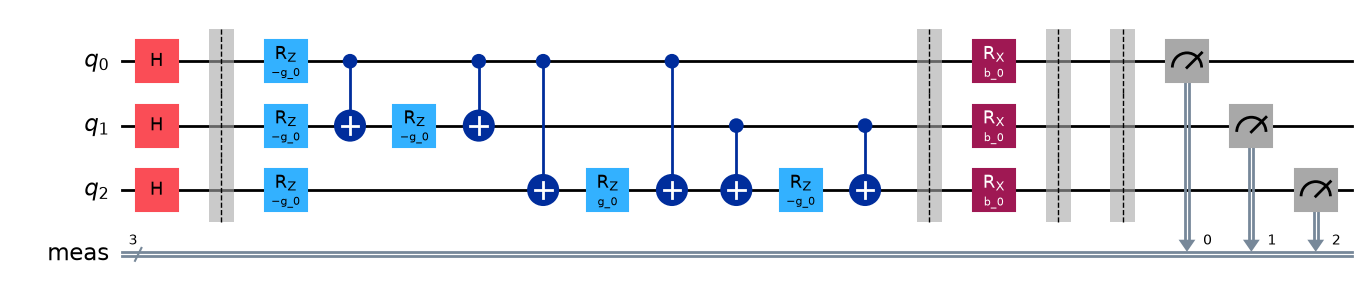

In [19]:
# QAOA circuits are multi-layer 
num_layers=1

pqc=QuantumCircuit(n)

# QAOA circuits start with 
pqc.h(range(n))

params={}

# adding layers 
for l in range(num_layers):
    
    gamma_label=f'g_{l}'     
    params[gamma_label]= Parameter(gamma_label)    
    
    beta_label=f'b_{l}' 
    params[beta_label]= Parameter(beta_label)    
    print(h.keys())

    pqc.barrier()
    for i in h.keys():
        pqc.rz(h[i]*params[gamma_label], i)

    print(J.keys())
    for i, j in J.keys():                
        pqc.cx(i, j)
        pqc.rz(J[i,j]*params[gamma_label], j)
        pqc.cx(i, j)

    #Mixer Hamiltonian
    pqc.barrier()
    for i in range(n):
        pqc.rx(params[beta_label], i)
    
    #end of the layer
    pqc.barrier()

pqc.measure_all()

# print(pqc)
pqc.draw('mpl')

## Tuning $\gamma$ and $\beta$

The circuit’s measurement distribution depends on $\gamma$ and $\beta$. A classical search tunes these parameters to minimize the **expected objective value**.

For each parameter pair, we:

1. Assign the values and run the QAOA circuit for $N$ shots.
2. Evaluate the objective value of each measured solution.
3. Compute the average cost, weighted by measurement frequency:

$$
\widehat{\mathrm{EV}}(\gamma,\beta)
=\frac{1}{N}\sum_x \mathrm{count}(x)\,f(x).
$$

Here, $x$ represents a solution in variable order. We reverse Qiskit’s measurement strings before calling `get_f`, ensuring that `x[i]` corresponds to variable $i$.

The classical search compares these estimates and retains the best parameter pair found. Lower expected cost means better solutions on average, although finite-shot estimates can vary between runs.

Grid points per parameter: 4
Parameter pairs to evaluate: 16
Shots per circuit: 1024

Grid search complete
  Best gamma: -0.5236 radians
  Best beta:  -1.5708 radians
  Estimated expected cost: -0.7969
  Exact global minimum:    -4.0000

Most frequent solutions at the best parameter pair:
  Solution     Cost      Count    Frequency
       111     -4.0        341       33.3%
       101      2.0        211       20.6%
       010      4.0        136       13.3%
       011     -2.0        120       11.7%


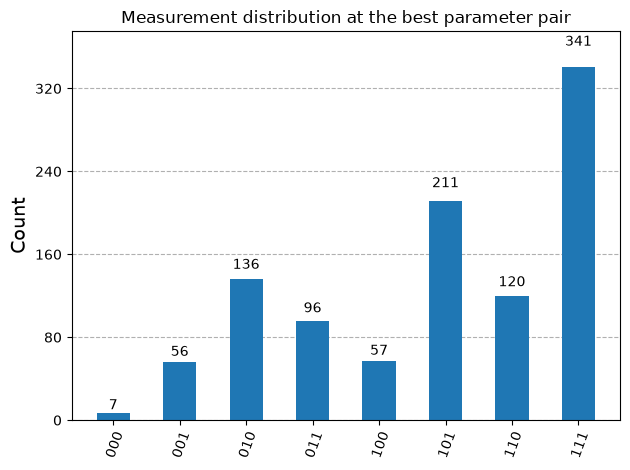

In [ ]:
shots = 1024

grid_points_per_parameter = 4
parameter_values = np.linspace(-np.pi / 2, np.pi / 2, grid_points_per_parameter)

best_solution = {'EV': np.inf}

print(f"Grid points per parameter: {grid_points_per_parameter}")
# print(f"Angle spacing: {parameter_values[1] - parameter_values[0]:.4f} radians")
print(f"Parameter pairs to evaluate: {grid_points_per_parameter**2}")
print(f"Shots per circuit: {shots}")
print()

# This two-parameter search requires a single QAOA layer.
assert num_layers == 1, "This grid search supports only one QAOA layer."
assert grid_points_per_parameter >= 2, "Use at least two grid points."

for g_val in parameter_values:
    for b_val in parameter_values:

        mapping = {gamma_label: g_val, beta_label: b_val}

        # assign_parameters returns a new circuit; pqc remains unchanged.
        new_circuit = pqc.assign_parameters(mapping)

        job = sampler.run([new_circuit], shots=shots)
        result_ideal = job.result()
        count_ideal = result_ideal[0].data.meas.get_counts()

        # Reverse Qiskit's bitstrings so index i corresponds to variable i.
        EV = 0.0
        for x, freq in count_ideal.items():
            f = get_f(h, J, x[::-1])
            EV += f * freq

        EV /= sum(count_ideal.values())

        if EV < best_solution['EV']:
            best_solution['EV'] = EV
            best_solution['count_ideal'] = count_ideal.copy()
            best_solution['params'] = (g_val, b_val)

best_gamma, best_beta = best_solution['params']

print("Grid search complete")
print(f"  Best gamma: {best_gamma:.4f} radians")
print(f"  Best beta:  {best_beta:.4f} radians")
print(f"  Estimated expected cost: {best_solution['EV']:.4f}")
print(f"  Exact global minimum:    {np.min(f_list):.4f}")
print()

_counter = Counter(best_solution['count_ideal'])
high_freq_x = _counter.most_common(4)
total_shots = sum(best_solution['count_ideal'].values())

print("Most frequent solutions at the best parameter pair:")
print(f"{'Solution':>10} {'Cost':>8} {'Count':>10} {'Frequency':>12}")

for x, freq in high_freq_x:
    solution = x[::-1]
    cost = get_f(h, J, solution)
    print(
        f"{solution:>10} {cost:>8.1f} "
        f"{freq:>10} {freq / total_shots:>11.1%}"
    )

# Histogram labels retain Qiskit's order: qubit n-1 ... qubit 0.
fig = plot_histogram(
    best_solution['count_ideal'],
    title="Measurement distribution at the best parameter pair"
)
fig

## Quantifying the Quality of Solutions
QAOA-specific metrics (metrics used for evaluating optimization techniques)

- Approximation Ratio (AR) 
$$AR=\frac{EV}{Global Minimum}$$

- Approximation Ratio Gap (ARG)

$$ ARG=100 \times \left| \frac{EV_{ideal} - EV_{noisy}}{EV_{ideal}} \right|$$

In [18]:
AR=best_solution['EV']/np.min(f_list)
print('Approximation Ratio (AR)=', AR)

Approximation Ratio (AR)= 0.19921875
